# EurecomGPT — Phase 2: train a tiny GPT & measure parallelism

Run this in **Google Colab** with a **GPU** runtime (Runtime -> Change runtime type -> T4 GPU). It exercises Lecture 3: CPU vectorization (SIMD), CPU threads and GPU (CUDA). The model code ships working; implementing it yourself (from `templates/`) is optional. The mandatory work is running this notebook end to end.

Run the cells **in order** — later cells reuse variables the earlier ones define (`data`, `sweep`, `cpu_s`, `GCS_URL`, ...), and the final report cell collects all of them. If you restart the runtime, start again from section 0.

## 0. Setup — clone your repo and install dependencies

Colab starts with an empty disk, so first pull in your own repository: that is where your `model.py`, `attention_numpy.py` and the helper modules live. Two packages are not preinstalled in Colab — `safetensors` (the weight format we save in) and `google-cloud-storage` (used in section 6 to publish the model).

In [3]:

# Clone your GitHub repository
!git clone https://github.com/vignesh14102003/eurecomgpt-lab.git repo 2>/dev/null || true

# Enter the repository folder
%cd repo

# Install additional packages required by this notebook
!pip -q install safetensors google-cloud-storage

# Add the Phase 2 folder to Python's import path
import sys
sys.path.insert(0, 'phase-2-tiny-gpt')


/content/repo/repo/repo


### Imports, and confirm the GPU is really attached

What each import is for:

- `attention_naive` / `attention_vectorized` — the two implementations of the *same* attention maths that section 1 times against each other.
- `CONFIG` — the model's hyperparameters (layers, heads, embedding width). Everything downstream builds the model from this one object.
- `GPT` — the transformer itself.
- `train` / `experiments` — provided helpers: batching, the training loop, sampling, the timing harnesses and the report writer.

**Check the printed device.** If it says `cpu`, the GPU runtime is not attached and section 4 will show no speedup — fix it with Runtime -> Change runtime type -> T4 GPU before going on.

In [4]:
import numpy as np, torch
from attention_numpy import attention_naive, attention_vectorized
from config import CONFIG
from model import GPT
import train, experiments

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device, '| torch', torch.__version__)

device: cuda | torch 2.11.0+cu130


In [5]:
!pwd
!git rev-parse --show-toplevel
!ls phase-2-tiny-gpt

/content/repo/repo/repo
/content/repo/repo/repo
attention_numpy.py  model.py	    README.md		    TASKS.md   train.py
config.py	    notebook.ipynb  reflection_template.md  templates
experiments.py	    __pycache__     requirements.txt	    tests


## 1. Attention: naive loops vs vectorized (SIMD)

Both functions compute *identical* attention output — the only difference is how they get there. `attention_naive` walks the sequence with Python loops, one dot product at a time. `attention_vectorized` hands whole matrices to NumPy, which dispatches to a BLAS library compiled with AVX/SIMD instructions that process several floats per CPU cycle.

`T=256` is the sequence length and `d=64` the head dimension — the same shapes the real model uses, so the timing is representative.

**What to look for:** a large speedup (often 100x or more) from code that is mathematically the same. `np.show_config()` prints which BLAS NumPy is linked against — that library is where the speedup actually comes from.

In [6]:
# Same maths, timed two ways. T = sequence length, d = head dimension.
t_naive = experiments.time_attention(attention_naive, T=256, d=64)
t_vec   = experiments.time_attention(attention_vectorized, T=256, d=64)
print(f'naive      : {t_naive:.2f} ms')
print(f'vectorized : {t_vec:.2f} ms   ({t_naive / t_vec:.1f}x faster)')

# Which BLAS is NumPy using? This is what makes the vectorized version fast.
np.show_config()

naive      : 460.34 ms
vectorized : 0.92 ms   (502.0x faster)
Build Dependencies:
  blas:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.13.0/lib/python3.13/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.13.0/lib/python3.13/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.27  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3.27
  lapack:
    detection method: pkgconfig
    found: true
    include directory: /opt/_internal/cpython-3.13.0/lib/python3.13/site-packages/scipy_openblas64/include
    lib directory: /opt/_internal/cpython-3.13.0/lib/python3.13/site-packages/scipy_openblas64/lib
    name: scipy-openblas
    openblas configuration: OpenBLAS 0.3.27  USE64BITINT DYNAMIC_ARCH NO_AFFINITY
      Haswell MAX_THREADS=64
    pc file directory: /project/.openblas
    version: 0.3

## 2. Load the training corpus

Everything from here on needs training data, so load it once into `data` and reuse it.

The text is TinyShakespeare (~1 MB). If your repo already contains `input.txt` it is used directly; otherwise it is downloaded. `train.encode` turns the characters into integer token ids, and the result becomes one long 1-D tensor that later cells slice batches out of.

**What to look for:** a token count around one million. A much smaller number means the download failed and later training will not converge.

In [7]:

import os, urllib.request

# Prefer a local copy if the repo has one; otherwise fetch TinyShakespeare (~1 MB).
if os.path.exists('phase-2-tiny-gpt/input.txt'):
    text = open(
        'phase-2-tiny-gpt/input.txt',
        encoding='utf-8',
        errors='replace'
    ).read()
else:
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    text = urllib.request.urlopen(url).read().decode('utf-8', 'replace')

# Encode characters into integer token IDs.
data = torch.tensor(train.encode(text), dtype=torch.long)

print('corpus tokens:', len(data))


corpus tokens: 1115394


## 3. Multi-threading: sweep CPU threads (intra-op parallelism)

PyTorch splits a single CPU operation — a matrix multiply, say — across `torch.set_num_threads(n)` worker threads. This is *intra-op* parallelism: one operation, many cores, as opposed to running several operations at once.

The cell below builds a fresh model, defines one training step (fetch a batch, forward, backward), and times that step at 1, 2, 4 and 8 threads.

**What to look for:** time per step falls as threads are added, then flattens or gets *worse*. That turning point is the contention point — the moment coordination costs more than the extra parallelism buys — and explaining where it lands is what your reflection is about.

In [8]:

model = GPT(CONFIG)

print('parameters:', model.num_params())

# One training step: sample a batch, forward pass, backward pass.
def one_step():
    x, y = train.get_batch(
        data,
        CONFIG.block_size,
        16,
        'cpu'
    )
    _, loss = model(x, y)
    loss.backward()

# Test different CPU thread counts.
sweep = experiments.threading_sweep(
    one_step,
    threads=(1, 2, 4, 8)
)

print('threads -> ms:', sweep)

print(
    'torch threads restored to:',
    torch.get_num_threads()
)


parameters: 4935680
threads -> ms: {'1': 2190.071, '2': 2282.54, '4': 2174.354, '8': 2262.978}
torch threads restored to: 1


### Plot the sweep

The same numbers as a curve, because the shape is the point — you are looking for where it stops going down. **Save this plot**: the deliverables ask for it, and your reflection should refer to it.

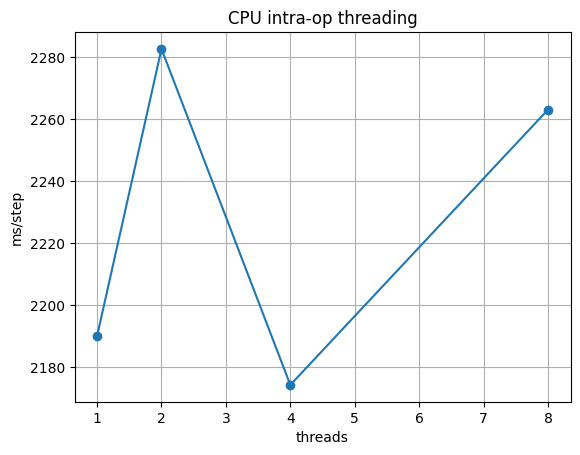

In [9]:

import matplotlib.pyplot as plt

# Convert thread counts into numbers and sort them.
ts = sorted(int(k) for k in sweep)

# Plot execution time against thread count.
plt.plot(
    ts,
    [sweep[str(t)] for t in ts],
    'o-'
)

plt.xlabel('threads')
plt.ylabel('ms/step')
plt.title('CPU intra-op threading')
plt.grid(True)

# Save the plot for your submission.
plt.savefig(
    'phase2_threading_sweep.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()


## 4. GPU (CUDA): the same training loop on a T4

Identical model, identical data, identical number of steps — the only thing that changes is the device. A GPU runs thousands of arithmetic units in parallel, which suits the dense matrix multiplies that dominate a transformer.

Two fresh models are built so neither run inherits the other's trained weights. `log_every=0` silences per-step logging so the timing is not distorted by printing.

**What to look for:** a large ratio — often 50x or more. If it is close to 1x, you are on a CPU runtime (check the device printed in section 0).

The CPU side of this comparison runs at PyTorch's default thread count, which section 3 restored after its sweep. Measured with the CPU still pinned to 8 threads on a 2-vCPU machine, the baseline would be fighting itself and the GPU would look better than it is.

In [11]:
# Run 100 training steps on CPU.
cpu_loss, cpu_s = train.train(
    GPT(CONFIG),
    data,
    steps=100,
    device='cpu',
    log_every=0
)

# Create a fresh model for GPU training.
gpu_model = GPT(CONFIG)

# Run the same 100 training steps on GPU.
gpu_loss, gpu_s = train.train(
    gpu_model,
    data,
    steps=100,
    device=device,
    log_every=0
)

# Compare execution time.
print(
    f'CPU 100 steps: {cpu_s*1000:.0f} ms | '
    f'{device} 100 steps: {gpu_s*1000:.0f} ms '
    f'({cpu_s/gpu_s:.1f}x)'
)

CPU 100 steps: 469676 ms | cuda 100 steps: 12717 ms (36.9x)


## 5. Train the model, generate a sample, save the weights

The real training run: 2000 steps on whichever device section 0 detected. This is the model you will publish and that Phase 4 will later serve.

`train.sample` then generates 200 tokens starting from a newline, and `save_model` writes `model.safetensors`.

**What to look for:** the loss should fall well below the random-initialisation value of about 5.55 — under 3.0 is the bar. The sample will not be Shakespeare, but it should look like text: words of plausible length, line breaks, capital letters after full stops. If the loss is still near 5.5 or the sample is noise, something upstream is wrong; do not publish it.

In [12]:
model = GPT(CONFIG)

final_loss, secs = train.train(
    model,
    data,
    steps=2000,
    device=device,
    log_every=200
)

print(f'final loss {final_loss:.3f} in {secs:.1f}s')

# Generate from a newline.
sample_text = train.sample(
    model,
    prompt='\n',
    max_new_tokens=200,
    device=device
)

print('----- sample -----\n' + sample_text)

# Save model weights.
train.save_model(model, 'model.safetensors')

step     0  loss 5.7258
step   200  loss 2.4553
step   400  loss 2.3565
step   600  loss 2.0836
step   800  loss 1.9119
step  1000  loss 1.8059
step  1200  loss 1.7364
step  1400  loss 1.6071
step  1600  loss 1.5598
step  1800  loss 1.5114
final loss 1.507 in 275.2s
----- sample -----


MARIANAN:
No; not Lord mord, Bornablack:
So talk Dorbiar, upon go son! This flower
To better he vinture.' Got id to thim not teble
As I experforted till thee hands: eversed ha--
How should be in the 


'model.safetensors'

## 6. Upload the weights to Cloud Storage (public)

The grader cannot see your Colab session, so the model has to be published somewhere reachable — a public Cloud Storage object. Phase 4 will load the same URL to serve your model.

Colab is **not** logged into `gcloud`, so authenticate this session first. The popup asks for the Google account that owns your Phase-0 project.

In [13]:
from google.colab import auth

auth.authenticate_user()

In [15]:
import json

with open('submission/phase0_report.json') as f:
    phase0 = json.load(f)

PROJECT = phase0['gcloud']['project']

print('Confirmed project ID:', PROJECT)

Confirmed project ID: eurecomcgpt-vigneshramkumar


Now create the bucket (if it does not exist), make it publicly readable, and upload.

**Set `PROJECT` to your own Phase-0 project id before running this.** Bucket names are globally unique across all of Google Cloud, which is why the project id is used as a prefix. The model is a few MB, comfortably inside the 5 GB free tier.

**What to look for:** the printed URL should download the file when you open it in a browser. Copy it — the report needs it, and so does Phase 4.

In [16]:
from google.cloud import storage

PROJECT = 'eurecomcgpt-vigneshramkumar'
BUCKET = f'{PROJECT}-eurecomgpt'

client = storage.Client(project=PROJECT)

try:
    bucket = client.get_bucket(BUCKET)
except Exception:
    bucket = client.create_bucket(BUCKET, location='US')

policy = bucket.get_iam_policy(requested_policy_version=3)

if not any(
    b['role'] == 'roles/storage.objectViewer'
    and 'allUsers' in b.get('members', set())
    for b in policy.bindings
):
    policy.bindings.append({
        'role': 'roles/storage.objectViewer',
        'members': {'allUsers'}
    })
    bucket.set_iam_policy(policy)

blob = bucket.blob('model.safetensors')
blob.upload_from_filename('model.safetensors')

GCS_URL = f'https://storage.googleapis.com/{BUCKET}/model.safetensors'

print('public URL:', GCS_URL)

public URL: https://storage.googleapis.com/eurecomcgpt-vigneshramkumar-eurecomgpt/model.safetensors


## 7. Write the submission report

This collects every measurement the notebook has taken into `submission/phase2_report.json` — the attention timings from section 1, the thread sweep from section 3, the CPU/GPU comparison from section 4, the training result and sample from section 5, and the public model URL from section 6.

That is why the cells must be run in order: this one fails with a `NameError` if any earlier section was skipped, and the name it complains about tells you which.

In [17]:
experiments.write_report(
    attention={
        'naive_ms': t_naive,
        'vectorized_ms': t_vec,
        'speedup': round(t_naive/t_vec, 2)
    },
    threads=sweep,
    devices={
        'cpu_ms': round(cpu_s*1000, 1),
        'gpu_ms': round(gpu_s*1000, 1)
    },
    training={
        'steps': 2000,
        'final_loss': round(final_loss, 4),
        'param_count': model.num_params()
    },
    sample_text=sample_text,
    gcs_url=GCS_URL,
)

Wrote submission/phase2_report.json


PosixPath('/content/repo/repo/repo/submission/phase2_report.json')

In [18]:
import json

with open('submission/phase2_report.json') as f:
    report = json.load(f)

print(json.dumps(report, indent=2))

{
  "phase": "2",
  "environment": {
    "colab": true
  },
  "attention": {
    "naive_ms": 460.339,
    "vectorized_ms": 0.917,
    "speedup": 502.01
  },
  "threads": {
    "1": 2190.071,
    "2": 2282.54,
    "4": 2174.354,
    "8": 2262.978
  },
  "devices": {
    "cpu_ms": 469675.5,
    "gpu_ms": 12716.7
  },
  "training": {
    "steps": 2000,
    "final_loss": 1.5074,
    "param_count": 4935680
  },
  "sample": "\n\nMARIANAN:\nNo; not Lord mord, Bornablack:\nSo talk Dorbiar, upon go son! This flower\nTo better he vinture.' Got id to thim not teble\nAs I experforted till thee hands: eversed ha--\nHow should be in the ",
  "model": {
    "gcs_url": "https://storage.googleapis.com/eurecomcgpt-vigneshramkumar-eurecomgpt/model.safetensors"
  }
}


In [19]:
!nproc

2


In [20]:

from pathlib import Path
import json
import subprocess
import re

# Read the report generated by the notebook.
report_path = Path('submission/phase2_report.json')
template_path = Path('phase-2-tiny-gpt/reflection_template.md')
output_path = Path('submission/phase2_reflection.md')

report = json.loads(report_path.read_text(encoding='utf-8'))
template = template_path.read_text(encoding='utf-8')

# Detect the number of available CPU cores.
vcpu_count = int(subprocess.check_output(
    ['nproc'], text=True
).strip())

# Extract actual experimental measurements.
a = report['attention']
t = report['threads']
d = report['devices']
training = report['training']

naive = a['naive_ms']
vectorized = a['vectorized_ms']
cpu_ms = d['cpu_ms']
gpu_ms = d['gpu_ms']
loss = training['final_loss']
speedup = a['speedup']

thread_improvement = (t['1'] - t['4']) / t['1'] * 100

# Human-written answers for the professor's reflection.
answers = {
    'attn_naive_ms': str(naive),
    'attn_vectorized_ms': str(vectorized),
    'cpu_ms': str(cpu_ms),
    'gpu_ms': str(gpu_ms),
    'final_loss': str(loss),

    'thread_sweep': (
        f"1 thread: {t['1']} ms; "
        f"2 threads: {t['2']} ms; "
        f"4 threads: {t['4']} ms; "
        f"8 threads: {t['8']} ms. "
        f"The fastest measured setting was "
        f"{min(t, key=t.get)} threads."
    ),

    'vectorization_why': (
        "Both attention functions calculate the same result, but "
        "the naive version performs many small dot products one "
        "after another. This creates repeated Python loop overhead "
        "and does not make full use of the CPU's processing "
        "capabilities. The vectorized version passes complete "
        "matrices to NumPy's compiled OpenBLAS routines. These "
        "use optimized native code and SIMD instructions such as "
        "AVX2 to process several values together. In my experiment, "
        f"this reduced execution time from {naive} ms to "
        f"{vectorized} ms, giving approximately {speedup}x speedup."
    ),

    'threading_plateau': (
        f"My Colab runtime exposed {vcpu_count} vCPUs. "
        f"The measured times were {t['1']} ms with one thread, "
        f"{t['2']} ms with two, {t['4']} ms with four, and "
        f"{t['8']} ms with eight threads. Four threads gave the "
        f"lowest recorded time, but the improvement over one "
        f"thread was only about {thread_improvement:.1f}%. "
        "The results therefore do not show consistent improvement "
        "as more threads are added. With limited CPU resources, "
        "using four or eight threads can oversubscribe the available "
        "cores. Threads also need to coordinate their operations, "
        "share memory and synchronize gradients, so this overhead "
        "can cancel out the benefit of additional parallelism."
    ),

    'gpu_why': (
        "A transformer training step involves many matrix "
        "multiplications in its attention and feed-forward layers, "
        "as well as gradient calculations. These operations contain "
        "many calculations that can be performed in parallel, "
        "which makes them suitable for a GPU. In my experiment, "
        f"100 training steps took {cpu_ms} ms on the CPU and "
        f"{gpu_ms} ms on the T4 GPU, giving a "
        f"{cpu_ms/gpu_ms:.1f}x speedup. A small sequential task "
        "or a file-reading operation would not benefit as much, "
        "because it has less parallel work and the overhead of "
        "moving data or launching GPU operations can outweigh "
        "the benefit."
    ),

    'parallelism_limit': (
        "These experiments showed me that parallelism is useful "
        "when the work can be divided into operations that the "
        "hardware can execute efficiently. In the attention test, "
        f"vectorization reduced execution time from {naive} ms "
        f"to {vectorized} ms, a {speedup}x improvement, because "
        "NumPy and OpenBLAS could use optimized matrix operations "
        "instead of repeated serial Python loops. The CPU threading "
        f"results were less impressive: one, two, four and eight "
        f"threads took {t['1']}, {t['2']}, {t['4']} and "
        f"{t['8']} ms respectively. The four-thread result was "
        f"only about {thread_improvement:.1f}% better than one "
        f"thread. Limited vCPUs and coordination overhead explain "
        "why adding workers did not consistently help. Finally, "
        f"100 training steps took {cpu_ms} ms on the CPU versus "
        f"{gpu_ms} ms on the T4, a {cpu_ms/gpu_ms:.1f}x speedup. "
        "Transformer matrix operations suit GPU parallelism, "
        "although serial operations and transferring data between "
        "the CPU and GPU remain limitations."
    ),

    'next_experiment': (
        "I would repeat the CPU and GPU training experiments using "
        "different batch sizes, such as 1, 16, 64 and 128. I would "
        "measure both execution time and data-transfer overhead "
        "after warm-up runs. This would help identify the workload "
        "size at which GPU acceleration becomes worthwhile. "
        "If the GPU remains much faster even with very small "
        "batches, I would reconsider how significant the overhead "
        "really is."
    )
}

# Replace TODOs while preserving the original grading markers.
for key, value in answers.items():
    pattern = rf"(<!--answer:{re.escape(key)}-->).*?(<!--/answer-->)"
    template, count = re.subn(
        pattern,
        lambda match: match.group(1) + value + match.group(2),
        template,
        count=1,
        flags=re.DOTALL
    )
    if count != 1:
        raise ValueError(f"Could not find the answer slot: {key}")

# Save the completed reflection.
output_path.write_text(template, encoding='utf-8')

print("Reflection successfully created!")
print("File:", output_path)
print("Detected vCPUs:", vcpu_count)
print("Answer slots completed:", len(answers))


Reflection successfully created!
File: submission/phase2_reflection.md
Detected vCPUs: 2
Answer slots completed: 11


In [21]:
print(Path('submission/phase2_reflection.md').read_text())

# Phase 2 — Reflection: where does parallelism stop helping?

Copy this file to `submission/phase2_reflection.md`, fill in every answer slot, and commit it:

```bash
cp phase-2-tiny-gpt/reflection_template.md submission/phase2_reflection.md
```

**How to fill it in.** Each answer sits between a pair of `<!--answer:...-->` markers. Replace
the `TODO` line with your answer — **leave the markers themselves untouched**, they are how the
grader finds your answers. Anything you write outside the markers is ignored, so add extra
prose, tables or your threading plot freely.

Numbers in section 1 must **match `submission/phase2_report.json`** — copy them across, do not
retype from memory; they are checked against it.

---

## 1. Your measurements

| | Value |
|---|---|
| Naive attention, ms (`attention.naive_ms`) | <!--answer:attn_naive_ms-->460.339<!--/answer--> |
| Vectorized attention, ms (`attention.vectorized_ms`) | <!--answer:attn_vectorized_ms-->0.917<!--/answer--> |
| CPU training, ms f

In [22]:
import subprocess
from pathlib import Path

# Find the actual Git repository root.
root = Path(subprocess.check_output(
    ['git', 'rev-parse', '--show-toplevel'],
    text=True
).strip())

print("Git repository:", root)

# Check the required Phase 2 files.
files = [
    'phase-2-tiny-gpt/attention_numpy.py',
    'phase-2-tiny-gpt/model.py',
    'phase-2-tiny-gpt/notebook.ipynb',
    'submission/phase2_report.json',
    'submission/phase2_reflection.md'
]

print("\nFile verification:")

for name in files:
    path = root / name
    print(
        "FOUND" if path.is_file() else "MISSING",
        name
    )

# Check pending Git changes.
print("\nGit status:")
result = subprocess.run(
    ['git', 'status', '--short'],
    cwd=root,
    capture_output=True,
    text=True,
    check=True
)

print(result.stdout or "No pending changes")

Git repository: /content/repo/repo/repo

File verification:
FOUND phase-2-tiny-gpt/attention_numpy.py
FOUND phase-2-tiny-gpt/model.py
FOUND phase-2-tiny-gpt/notebook.ipynb
FOUND submission/phase2_report.json
FOUND submission/phase2_reflection.md

Git status:
?? model.safetensors
?? phase2_threading_sweep.png
?? submission/phase2_reflection.md
?? submission/phase2_report.json



In [23]:
!python -m pytest phase-2-tiny-gpt/tests -p autograder.points -q

.........                                                                [100%]
========================== AUTOGRADER SCORE: 75 / 75 ===========================
  [PASS]  15/15  phase-2-tiny-gpt/tests/test_model.py::test_param_count_is_a_tiny_gpt
  [PASS]  20/20  phase-2-tiny-gpt/tests/test_model.py::test_architecture_matches_spec
  [PASS]  15/15  phase-2-tiny-gpt/tests/test_report.py::test_all_measurements_present
  [PASS]  15/15  phase-2-tiny-gpt/tests/test_report.py::test_parallelism_helped
  [PASS]  10/10  phase-2-tiny-gpt/tests/test_report.py::test_training_and_model_recorded
  [PASS]   0/0   phase-2-tiny-gpt/tests/test_units.py::test_naive_matches_reference
  [PASS]   0/0   phase-2-tiny-gpt/tests/test_units.py::test_vectorized_matches_reference
  [PASS]   0/0   phase-2-tiny-gpt/tests/test_units.py::test_naive_and_vectorized_agree
  [PASS]   0/0   phase-2-tiny-gpt/tests/test_units.py::test_output_shape_and_rows_sum_like_softmax
9 passed in 0.31s


In [26]:
%cd /content/repo/repo/repo

!pwd
!git rev-parse --show-toplevel
!git remote -v
!git status --short
!ls -l submission/phase2_report.json submission/phase2_reflection.md

/content/repo/repo/repo
/content/repo/repo/repo
/content/repo/repo/repo
origin	https://github.com/vignesh14102003/eurecomgpt-lab.git (fetch)
origin	https://github.com/vignesh14102003/eurecomgpt-lab.git (push)
?? model.safetensors
?? phase2_threading_sweep.png
?? submission/phase2_reflection.md
?? submission/phase2_report.json
-rw-r--r-- 1 root root 6281 Nov  1 18:19 submission/phase2_reflection.md
-rw-r--r-- 1 root root  757 Nov  1 18:16 submission/phase2_report.json


In [27]:
%cd /content/repo/repo/repo

!git add phase-2-tiny-gpt/attention_numpy.py phase-2-tiny-gpt/model.py submission/phase2_report.json submission/phase2_reflection.md

!git status --short

/content/repo/repo/repo
A  submission/phase2_reflection.md
A  submission/phase2_report.json
?? model.safetensors
?? phase2_threading_sweep.png


In [29]:
%cd /content/repo/repo/repo

!git config user.name "Vignesh Ramkumar"
!git config user.email "Vignesh.Ramkumar@eurecom.fr"

!git config --get user.name
!git config --get user.email

/content/repo/repo/repo
Vignesh Ramkumar
Vignesh.Ramkumar@eurecom.fr


In [30]:
!git commit -m "Complete Phase 2 GPT experiments"

[main 4faf4b6] Complete Phase 2 GPT experiments
 2 files changed, 101 insertions(+)
 create mode 100644 submission/phase2_reflection.md
 create mode 100644 submission/phase2_report.json


In [32]:
import os
import getpass
import subprocess
from pathlib import Path

token = getpass.getpass("Paste your GitHub token (hidden): ")

askpass = Path("/tmp/git-askpass.sh")

askpass.write_text(
    '#!/bin/sh\n'
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *) echo "$GITHUB_TOKEN" ;;\n'
    'esac\n'
)

askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = token
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    result = subprocess.run(
        ["git", "push", "origin", "main"],
        cwd="/content/repo/repo/repo",
        env=env,
        capture_output=True,
        text=True
    )

    print(result.stdout)
    print(result.stderr)

    if result.returncode == 0:
        print("GitHub push successful!")

finally:
    env.pop("GITHUB_TOKEN", None)
    token = None
    askpass.unlink(missing_ok=True)

Paste your GitHub token (hidden): ··········

To https://github.com/vignesh14102003/eurecomgpt-lab.git
   8eb3ee2..4faf4b6  main -> main

GitHub push successful!


Now **commit** `submission/phase2_report.json` and push (see TASKS.md). Your CI + the instructor grade the report + your public model.